The decission trees are a method of unsupervised learning unparametrized

Decision trees classifiers

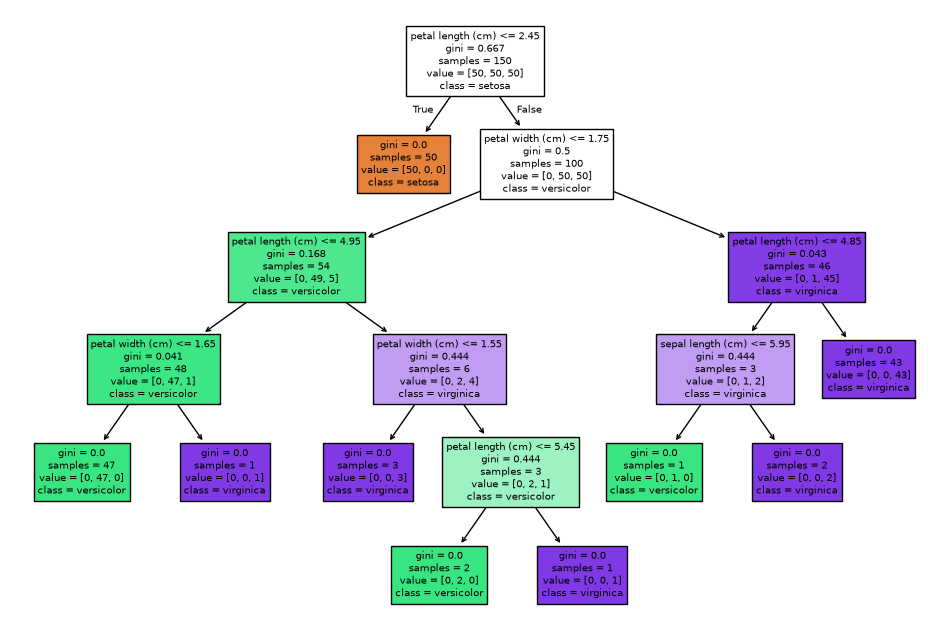

In [1]:
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

iris = load_iris()
X = iris.data
y = iris.target
tree_clf = DecisionTreeClassifier(random_state=42).fit(X, y)
plt.figure(figsize=(12,8))
plot_tree(tree_clf,
          feature_names=iris.feature_names, 
          class_names=list(iris.target_names),
          filled=True)
plt.show()

## Looking at the data

The dataset has no conditions stored in it. It is just a table, like the employees one: 4 measurement columns (the inputs) and a species column (the answer). The tree **creates** the conditions during `fit()` by looking for cut-off values that separate the species.

In [2]:
import pandas as pd

# Same data as X and y, but as a table: one row per flower
df = pd.DataFrame(X, columns=iris.feature_names)
df["species"] = pd.Categorical.from_codes(y, iris.target_names)  # turn 0/1/2 into names

df.sample(10, random_state=1)  # 10 random rows (df.head() would only show setosas)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
14,5.8,4.0,1.2,0.2,setosa
98,5.1,2.5,3.0,1.1,versicolor
75,6.6,3.0,4.4,1.4,versicolor
16,5.4,3.9,1.3,0.4,setosa
131,7.9,3.8,6.4,2.0,virginica
56,6.3,3.3,4.7,1.6,versicolor
141,6.9,3.1,5.1,2.3,virginica
44,5.1,3.8,1.9,0.4,setosa
29,4.7,3.2,1.6,0.2,setosa
120,6.9,3.2,5.7,2.3,virginica


In [3]:
# Average measurements per species: setosa has much smaller petals than the other two
df.groupby("species", observed=True).mean().round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
species,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


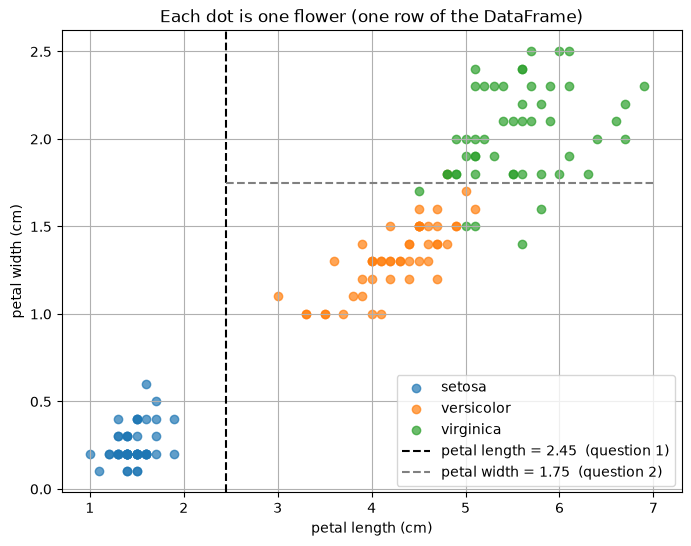

In [4]:
# Draw the flowers as points, using the two features the tree uses most.
# The dashed lines are the tree's first two questions (thresholds read from the tree plot above).
colors = {"setosa": "tab:blue", "versicolor": "tab:orange", "virginica": "tab:green"}

plt.figure(figsize=(8, 6))
for name, group in df.groupby("species", observed=True):
    plt.scatter(group["petal length (cm)"], group["petal width (cm)"],
                c=colors[name], label=name, alpha=0.7)

plt.axvline(2.45, color="black", linestyle="--", label="petal length = 2.45  (question 1)")
plt.hlines(1.75, xmin=2.45, xmax=7, color="gray", linestyle="--",
           label="petal width = 1.75  (question 2)")

plt.xlabel("petal length (cm)")
plt.ylabel("petal width (cm)")
plt.title("Each dot is one flower (one row of the DataFrame)")
plt.legend()
plt.grid(True)
plt.show()

## Decision tree regressor

The same idea as the classifier, but the answer is a **number** (salary) instead of a category (species).

How it works:
1. The tree splits the data using the independent variable (`YearsExperience`), for example "years <= 6.15?".
2. It keeps splitting each part with more conditions until it reaches the limit (`max_depth`), which leaves the workers divided into groups.
3. For each group it calculates the **mean salary** of the workers inside it.
4. To predict a new worker, it answers the questions until it lands in a group, and returns that group's mean.

The mean sits in the middle of the group's high and low salaries, so it is the best single guess for anyone who falls in that group. The tree picks its cuts so the salaries inside each group are as similar as possible, which keeps those means close to the real values.

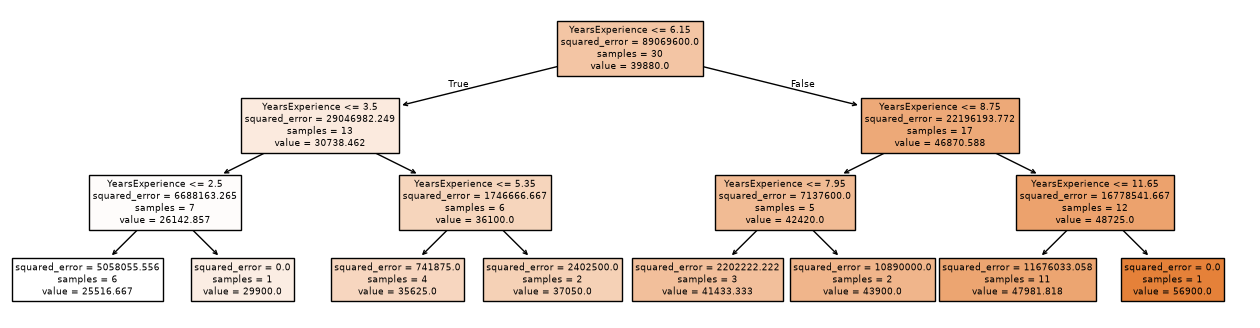

In [5]:
from sklearn.tree import DecisionTreeRegressor
import pandas as pd
import numpy as np

# Same workers as in linear_regression.ipynb (same seed), with a bit more noise (4_000 instead of 3_000)
rng = np.random.default_rng(seed=42)
years = rng.uniform(0, 12, size=30).round(1)                         # independent variable (X)
salary = 22_000 + 2_600 * years + rng.normal(0, 4_000, size=30)      # dependent variable (y)
df = pd.DataFrame({'YearsExperience': years, 'Salary': salary.round(-2)})

# fit() builds the tree:
#   1. Try every possible cut on YearsExperience (between each pair of neighbouring workers).
#   2. Keep the cut that leaves the salaries on each side as similar as possible
#      (lowest squared error).
#   3. Repeat inside each side, until max_depth=3 questions in a row -> at most 2**3 = 8 groups.
#   4. Each final group (leaf) stores the MEAN salary of its workers. That mean is the prediction.
tree_reg = DecisionTreeRegressor(max_depth=3, random_state=42).fit(df[['YearsExperience']], df['Salary'])

# Each box shows:
#   YearsExperience <= 6.15  -> the question (True = left, False = right)
#   squared_error            -> how spread out the salaries are in the box (in euros², so the numbers are huge)
#   samples                  -> how many workers reach the box
#   value                    -> the mean salary of those workers (in a leaf, this is the prediction)
plt.figure(figsize=(16,4))
plot_tree(tree_reg, filled=True, feature_names=['YearsExperience'])
plt.show()

In [6]:
# Follow one prediction: a worker with 4.5 years
#   4.5 <= 6.15? yes -> left
#   4.5 <= 3.50? no  -> right
#   4.5 <= 5.35? yes -> left -> leaf (a group of 4 workers)
new_worker = pd.DataFrame({'YearsExperience': [4.5]})
print("Prediction for 4.5 years:", tree_reg.predict(new_worker)[0])

# apply() says which leaf each worker falls into. Show the workers that share 4.5's leaf:
leaf = tree_reg.apply(new_worker)[0]
same_leaf = df[tree_reg.apply(df[['YearsExperience']]) == leaf]
print(same_leaf)
print("Mean salary of this group:", same_leaf['Salary'].mean())  # same number as the prediction

Prediction for 4.5 years: 35625.0
    YearsExperience   Salary
1               5.3  34200.0
10              4.4  36400.0
14              5.3  36200.0
21              4.3  35700.0
Mean salary of this group: 35625.0


### What to notice

- **Staircase, not a line.** Everyone in the same group gets the same prediction: 1.5 and 2.5 years both predict about 25,500. Linear regression would add the same amount for every extra year.
- **Groups with 1 worker** (2.5–3.5 years and > 11.65 years) are memorized points, not patterns. This is overfitting. `min_samples_leaf=3` would forbid groups that small.
- **No extrapolation.** Someone with 20 years still lands in the last group (> 11.65), so the prediction stays at 56,900. A line keeps going up.
- **Which model is better here?** Salary grows steadily with experience, so linear regression fits this data better. Trees are a better fit when the data has thresholds ("if more than X, then...") instead of a straight trend.